# Phase 7: Walk-Forward Backtest

Every game in the test seasons was predicted using only data from before it (`backtest_season.py`,
`run_baselines.py`). This notebook scores the predictions.

**Sections**
1. Setup (loads whichever backtest files exist)
2. Data checks: complete, leak-free, sampler healthy
3. Who predicts best? Track B vs baselines *(the main result)*
4. Head-to-head: paired differences with uncertainty
5. Calibration: is Track B too cautious? *(the Phase 6 question)*
6. Calibration over the season: is early season the problem?
7. Uncertainty intervals on P(win)
8. Score outputs: totals and puck lines
9. Combining Track B and rolling xG (for v1.1, xG is already inside: a blend shouldn't help much)
10. Market comparison (when closing-line data is available)

Lower log loss / Brier is better. A coin flip scores log loss 0.6931. Differences of 0.002-0.005 in log loss
are meaningful in hockey; section 4 says whether they're bigger than luck.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config.settings import OUTPUT_DIR
from src.data.db import get_connection
from src.validation.scoring import (score_models, calibration_table, calibration_slope, paired_difference,
                                    by_group, score_outputs, log_loss)

def check(label, ok, note=""):
    print(f"{'PASS ' if ok else 'CHECK'}  {label}" + (f"   ({note})" if note else ""))

BT = OUTPUT_DIR / "backtests"
SEASONS = ["20242025", "20252026"]
# Every Track B backtest present: files named <label>_<season>_scored.csv,
# label like trackb_w730 (v1, goals only), trackbxg_w365_hl120 (v1.1, xG + goals),
# trackbtv_w730 (v2.0, time-varying, weekly steps), trackbtv_w730_s2 (2-day steps),
# trackbtv_w730_r / _rh (v2.0d: + back-to-backs / + season home ice), _rg (v2.0e: + rest on goals per xG), _rt (v2.0f: + travel), _r_lg / _r_lxg (v2.1: xG-layer goalie / + shooter-adjusted xG)
LABELS = sorted({f.name.rsplit("_", 2)[0] for f in BT.glob("trackb*_scored.csv")})

def display_name(label):
    parts = label.split("_")
    version = {"trackbxg": "v1.1 xG", "trackbtv": "v2.0 TV"}.get(parts[0], "v1")
    extra = [f"{int(parts[1][1:]) // 365}-yr"]
    for p in parts[2:]:
        if p.startswith("hl"):
            extra.append(f"half-life {p[2:]}d")
        elif p.startswith("s") and p[1:].isdigit():
            extra.append(f"{p[1:]}-day steps")
        elif p.startswith("l") and len(p) > 1 and set(p[1:]) <= {"x", "g", "u"}:   # v2.1: _lx / _lg; v2.2: _lu
            extra.append(" + ".join({"x": "layer xG", "g": "layer goalie", "u": "lineup"}[ch] for ch in p[1:]))
        elif set(p) <= {"r", "g", "t", "k", "h"}:       # v2.0d: r rest, h home drift; v2.0e: g; v2.0f: t; v2.0g: k
            extra.append(" + ".join({"r": "rest", "g": "rest on finishing", "t": "travel",
                                     "k": "goalie rest", "h": "home drift"}[ch] for ch in p))
    if parts[0] == "trackbtv" and not any(p.startswith("s") and p[1:].isdigit() for p in parts[2:]):
        extra.append("weekly steps")
    return f"Track B {version} ({', '.join(extra)})"

frames = []
for season in SEASONS:
    base_path = BT / f"baselines_{season}.csv"
    if not base_path.exists():
        print(f"missing {base_path.name}: run py -m src.pipelines.run_baselines --seasons {season}")
        continue
    base = pd.read_csv(base_path)[["game_id", "p_home_rate", "p_elo", "p_rolling_xg"]]
    tb = None
    for lab in LABELS:
        f = BT / f"{lab}_{season}_scored.csv"
        if not f.exists():
            print(f"not yet: {f.name}")
            continue
        d = pd.read_csv(f, parse_dates=["game_date"])
        if d["game_id"].duplicated().any():          # e.g. two runs wrote to one file: never let it repeat games
            print(f"WARNING {f.name}: {d['game_id'].duplicated().sum()} duplicated games, kept the last of each. "
                  f"Run py .\\scripts\\check_backtests.py and rerun that season with --restart.")
            d = d.drop_duplicates("game_id", keep="last")
        keep = d[["game_id", "p_home", "p_home_lo", "p_home_hi", "sim_p_home", "refit_date", "train_games", "divergences"]]
        keep = keep.rename(columns={c: f"{c}_{lab}" for c in keep.columns if c != "game_id"})
        if tb is None:
            tb = d.drop(columns=["p_home", "p_home_lo", "p_home_hi", "sim_p_home", "refit_date", "train_games",
                                 "divergences", "model"]).merge(keep, on="game_id")
        else:
            tb = tb.merge(keep, on="game_id", how="outer")
    if tb is not None:
        frames.append(tb.merge(base, on="game_id", how="left"))

df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
df["season"] = df["season"].astype(str)
df["month"] = df["game_date"].dt.to_period("M").astype(str)
AVAILABLE = [lab for lab in LABELS if f"p_home_{lab}" in df]
# A model is compared only if it has a prediction for every game (a partial run would make every comparison NaN)
for lab in [l for l in AVAILABLE if df[f"p_home_{l}"].isna().any()]:
    n = df[f"p_home_{lab}"].notna().sum()
    print(f"LEFT OUT {display_name(lab)}: predictions for {n:,} of {len(df):,} games (run unfinished or a season missing)")
    AVAILABLE.remove(lab)
MODELS = {display_name(lab): f"p_home_{lab}" for lab in AVAILABLE}
MODELS.update({"home rate": "p_home_rate", "Elo": "p_elo", "rolling xG": "p_rolling_xg"})
print(f"games: {len(df):,}   seasons: {sorted(df.season.unique())}")
print("Track B versions:", ", ".join(display_name(l) for l in AVAILABLE))

games: 2,624   seasons: ['20242025', '20252026']
Track B versions: Track B v1 (1-yr), Track B v1 (2-yr), Track B v2.0 TV (2-yr, weekly steps), Track B v2.0 TV (2-yr, rest, weekly steps), Track B v2.0 TV (2-yr, rest, layer goalie, weekly steps), Track B v2.0 TV (2-yr, rest, lineup, weekly steps), Track B v2.0 TV (2-yr, rest, layer xG + layer goalie, weekly steps), Track B v2.0 TV (2-yr, rest + rest on finishing, weekly steps), Track B v2.0 TV (2-yr, rest + home drift, weekly steps), Track B v2.0 TV (2-yr, rest + travel, weekly steps), Track B v2.0 TV (2-yr, 2-day steps), Track B v1.1 xG (1-yr), Track B v1.1 xG (1-yr, half-life 60d), Track B v1.1 xG (1-yr, half-life 90d), Track B v1.1 xG (2-yr, half-life 180d)


C:\Users\ckief\AppData\Local\Temp\ipykernel_10304\2634817928.py:74: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["month"] = df["game_date"].dt.to_period("M").astype(str)


## 2. Data checks

In [2]:
for s in sorted(df.season.unique()):
    sub = df[df.season == s]
    check(f"{s}: all 1,312 games predicted", len(sub) == 1312, f"{len(sub):,}")
for lab in AVAILABLE:
    c = f"p_home_{lab}"; w = display_name(lab)
    check(f"{w}: no missing predictions", df[c].notna().all(), f"{df[c].isna().sum()} missing")
    leak = (pd.to_datetime(df[f"refit_date_{lab}"]) > df["game_date"]).sum()
    check(f"{w}: every refit happened before the game it predicts (no leakage)", leak == 0)
    div = df.groupby(f"refit_date_{lab}")[f"divergences_{lab}"].first()
    check(f"{w}: no divergences in any weekly fit", div.sum() == 0,
          f"{int(div.sum())} total over {len(div)} fits")
    gap = (df[f"sim_p_home_{lab}"] - df[c]).abs().mean()
    check(f"{w}: score-state simulator agrees with exact P(win)", gap < 0.015, f"mean |diff| {gap:.4f}")
    print(f"   training games per fit: {df[f'train_games_{lab}'].min():,} to {df[f'train_games_{lab}'].max():,}")
check("baselines present for every game", df[["p_home_rate", "p_elo", "p_rolling_xg"]].notna().all().all())

PASS   20242025: all 1,312 games predicted   (1,312)
PASS   20252026: all 1,312 games predicted   (1,312)
PASS   Track B v1 (1-yr): no missing predictions   (0 missing)
PASS   Track B v1 (1-yr): every refit happened before the game it predicts (no leakage)
PASS   Track B v1 (1-yr): no divergences in any weekly fit   (0 total over 53 fits)
PASS   Track B v1 (1-yr): score-state simulator agrees with exact P(win)   (mean |diff| 0.0063)
   training games per fit: 1,304 to 1,388
PASS   Track B v1 (2-yr): no missing predictions   (0 missing)
PASS   Track B v1 (2-yr): every refit happened before the game it predicts (no leakage)
PASS   Track B v1 (2-yr): no divergences in any weekly fit   (0 total over 53 fits)
PASS   Track B v1 (2-yr): score-state simulator agrees with exact P(win)   (mean |diff| 0.0066)
   training games per fit: 2,590 to 2,728
PASS   Track B v2.0 TV (2-yr, weekly steps): no missing predictions   (0 missing)
PASS   Track B v2.0 TV (2-yr, weekly steps): every refit happened 

## 3. Who predicts best?

Per season and combined. The **calibration slope** is 1 when probabilities are right on average,
above 1 when they're too cautious (favorites win more often than predicted), below 1 when too confident.

In [3]:
tables = {}
for label, sub in [(s, df[df.season == s]) for s in sorted(df.season.unique())] + [("combined", df)]:
    t = score_models(sub, MODELS, reference="home rate")
    tables[label] = t
    print(f"\n=== {label} ({len(sub):,} games) ===")
    display(t.drop(columns=["games"]).round(4))

comb = tables["combined"].set_index("model")
best = comb["log loss"].idxmin()
print(f"\nBest overall by log loss: {best}")
for name in [m for m in MODELS if m.startswith("Track B")]:
    check(f"{name} beats the home-rate baseline", comb.loc[name, "log loss"] < comb.loc["home rate", "log loss"])
    check(f"{name} beats Elo", comb.loc[name, "log loss"] < comb.loc["Elo", "log loss"])
    check(f"{name} beats rolling xG", comb.loc[name, "log loss"] < comb.loc["rolling xG", "log loss"],
          "the strongest baseline" + ("; v1 never sees xG" if "v1 (" in name else "; v1.1 should beat it"))


=== 20242025 (1,312 games) ===


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept,vs home rate,vs home rate 90%
0,Track B v1 (1-yr),0.6677,0.2375,0.6052,1.3130,"[1.09, 1.63]",0.0650,-0.0192,"[-0.0263, -0.0124]"
1,Track B v1 (2-yr),0.6686,0.2380,0.5953,0.9888,"[0.80, 1.24]",0.1230,-0.0184,"[-0.0275, -0.0097]"
2,"Track B v2.0 TV (2-yr, weekly steps)",0.6652,0.2364,0.5976,1.1220,"[0.93, 1.40]",0.1070,-0.0218,"[-0.0306, -0.0130]"
3,"Track B v2.0 TV (2-yr, rest, weekly steps)",0.6632,0.2354,0.5960,1.1657,"[0.97, 1.43]",0.0986,-0.0238,"[-0.0321, -0.0153]"
4,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",0.6629,0.2353,0.5991,1.0842,"[0.90, 1.33]",0.1100,-0.0241,"[-0.0327, -0.0151]"
5,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",0.6614,0.2346,0.5968,1.2017,"[1.01, 1.48]",0.0956,-0.0256,"[-0.0343, -0.0166]"
6,"Track B v2.0 TV (2-yr, rest, layer xG + layer ...",0.6630,0.2354,0.6014,1.0494,"[0.87, 1.29]",0.1149,-0.0240,"[-0.0331, -0.0146]"
7,"Track B v2.0 TV (2-yr, rest + rest on finishin...",0.6624,0.2351,0.5983,1.1657,"[0.97, 1.43]",0.0983,-0.0246,"[-0.0333, -0.0160]"
8,"Track B v2.0 TV (2-yr, rest + home drift, week...",0.6636,0.2356,0.5991,1.1617,"[0.96, 1.43]",0.1099,-0.0234,"[-0.0317, -0.0148]"
9,"Track B v2.0 TV (2-yr, rest + travel, weekly s...",0.6631,0.2354,0.5922,1.1624,"[0.95, 1.44]",0.0990,-0.0238,"[-0.0324, -0.0151]"



=== 20252026 (1,312 games) ===


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept,vs home rate,vs home rate 90%
0,Track B v1 (1-yr),0.6918,0.2493,0.5236,0.5846,"[0.18, 1.02]",-0.0049,-0.0010,"[-0.0059, +0.0038]"
1,Track B v1 (2-yr),0.6937,0.2502,0.5259,0.4507,"[0.16, 0.76]",0.0185,0.0008,"[-0.0060, +0.0077]"
2,"Track B v2.0 TV (2-yr, weekly steps)",0.6845,0.2457,0.5450,0.8187,"[0.52, 1.07]",-0.0392,-0.0084,"[-0.0152, -0.0012]"
3,"Track B v2.0 TV (2-yr, rest, weekly steps)",0.6833,0.2451,0.5465,0.8494,"[0.55, 1.09]",-0.0407,-0.0096,"[-0.0167, -0.0020]"
4,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",0.6830,0.2450,0.5480,0.8128,"[0.53, 1.05]",-0.0321,-0.0099,"[-0.0174, -0.0018]"
5,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",0.6838,0.2454,0.5457,0.8172,"[0.54, 1.06]",-0.0356,-0.0091,"[-0.0162, -0.0013]"
6,"Track B v2.0 TV (2-yr, rest, layer xG + layer ...",0.6827,0.2448,0.5526,0.8057,"[0.54, 1.04]",-0.0319,-0.0102,"[-0.0180, -0.0020]"
7,"Track B v2.0 TV (2-yr, rest + rest on finishin...",0.6833,0.2451,0.5457,0.8333,"[0.56, 1.07]",-0.0363,-0.0096,"[-0.0168, -0.0019]"
8,"Track B v2.0 TV (2-yr, rest + home drift, week...",0.6828,0.2449,0.5419,0.8650,"[0.58, 1.12]",-0.0388,-0.0101,"[-0.0172, -0.0025]"
9,"Track B v2.0 TV (2-yr, rest + travel, weekly s...",0.6834,0.2452,0.5457,0.8455,"[0.55, 1.09]",-0.0396,-0.0095,"[-0.0166, -0.0020]"



=== combined (2,624 games) ===


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept,vs home rate,vs home rate 90%
0,Track B v1 (1-yr),0.6798,0.2434,0.5644,1.0638,"[0.82, 1.28]",0.0080,-0.0101,"[-0.0142, -0.0059]"
1,Track B v1 (2-yr),0.6811,0.2441,0.5606,0.7858,"[0.59, 0.95]",0.0566,-0.0088,"[-0.0141, -0.0032]"
2,"Track B v2.0 TV (2-yr, weekly steps)",0.6749,0.2411,0.5713,0.9828,"[0.80, 1.15]",0.0289,-0.0151,"[-0.0204, -0.0093]"
3,"Track B v2.0 TV (2-yr, rest, weekly steps)",0.6732,0.2403,0.5713,1.0214,"[0.83, 1.19]",0.0241,-0.0167,"[-0.0221, -0.0109]"
4,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",0.6729,0.2402,0.5736,0.9620,"[0.79, 1.11]",0.0347,-0.0170,"[-0.0228, -0.0109]"
5,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",0.6726,0.2400,0.5713,1.0265,"[0.86, 1.19]",0.0242,-0.0173,"[-0.0227, -0.0117]"
6,"Track B v2.0 TV (2-yr, rest, layer xG + layer ...",0.6728,0.2401,0.5770,0.9391,"[0.77, 1.08]",0.0375,-0.0171,"[-0.0231, -0.0107]"
7,"Track B v2.0 TV (2-yr, rest + rest on finishin...",0.6728,0.2401,0.5720,1.0146,"[0.83, 1.18]",0.0260,-0.0171,"[-0.0226, -0.0112]"
8,"Track B v2.0 TV (2-yr, rest + home drift, week...",0.6732,0.2403,0.5705,1.0243,"[0.84, 1.19]",0.0310,-0.0167,"[-0.0221, -0.0109]"
9,"Track B v2.0 TV (2-yr, rest + travel, weekly s...",0.6733,0.2403,0.5690,1.0187,"[0.83, 1.18]",0.0247,-0.0167,"[-0.0219, -0.0107]"



Best overall by log loss: Track B v2.0 TV (2-yr, rest, lineup, weekly steps)
PASS   Track B v1 (1-yr) beats the home-rate baseline
PASS   Track B v1 (1-yr) beats Elo
CHECK  Track B v1 (1-yr) beats rolling xG   (the strongest baseline; v1 never sees xG)
PASS   Track B v1 (2-yr) beats the home-rate baseline
PASS   Track B v1 (2-yr) beats Elo
CHECK  Track B v1 (2-yr) beats rolling xG   (the strongest baseline; v1 never sees xG)
PASS   Track B v2.0 TV (2-yr, weekly steps) beats the home-rate baseline
PASS   Track B v2.0 TV (2-yr, weekly steps) beats Elo
PASS   Track B v2.0 TV (2-yr, weekly steps) beats rolling xG   (the strongest baseline; v1.1 should beat it)
PASS   Track B v2.0 TV (2-yr, rest, weekly steps) beats the home-rate baseline
PASS   Track B v2.0 TV (2-yr, rest, weekly steps) beats Elo
PASS   Track B v2.0 TV (2-yr, rest, weekly steps) beats rolling xG   (the strongest baseline; v1.1 should beat it)
PASS   Track B v2.0 TV (2-yr, rest, layer goalie, weekly steps) beats the home-r

## 4. Head-to-head: is the difference bigger than luck?

Paired comparison on the same games, resampled 2,000 times. Negative = the first model is better.
"share of resamples" is how often the first model came out ahead.

In [4]:
pairs = []
tb_names = [m for m in MODELS if m.startswith("Track B")]
for a in tb_names:
    for b in ["rolling xG", "Elo", "home rate"] + [x for x in tb_names if x != a]:
        r = paired_difference(df, MODELS[a], MODELS[b])
        pairs.append({"A": a, "B": b, "log loss A - B": r["difference"],
                      "90% range": f"[{r['lo']:+.4f}, {r['hi']:+.4f}]",
                      "share of resamples A better": r["share_of_boots_A_better"]})
pairs = pd.DataFrame(pairs)
display(pairs.round(4))

,A,B,log loss A - B,90% range,share of resamples A better
0,Track B v1 (1-yr),rolling xG,0.0044,"[-0.0006, +0.0093]",0.0750
1,Track B v1 (1-yr),Elo,-0.0024,"[-0.0064, +0.0014]",0.8345
2,Track B v1 (1-yr),home rate,-0.0101,"[-0.0143, -0.0059]",1.0000
3,Track B v1 (1-yr),Track B v1 (2-yr),-0.0013,"[-0.0039, +0.0012]",0.8020
4,Track B v1 (1-yr),"Track B v2.0 TV (2-yr, weekly steps)",0.0049,"[+0.0020, +0.0077]",0.0025
...,...,...,...,...,...
250,"Track B v1.1 xG (2-yr, half-life 180d)","Track B v2.0 TV (2-yr, rest + travel, weekly s...",0.0031,"[+0.0012, +0.0048]",0.0020
251,"Track B v1.1 xG (2-yr, half-life 180d)","Track B v2.0 TV (2-yr, 2-day steps)",0.0014,"[-0.0002, +0.0029]",0.0745
252,"Track B v1.1 xG (2-yr, half-life 180d)",Track B v1.1 xG (1-yr),-0.0010,"[-0.0022, +0.0002]",0.9205
253,"Track B v1.1 xG (2-yr, half-life 180d)","Track B v1.1 xG (1-yr, half-life 60d)",-0.0007,"[-0.0027, +0.0013]",0.7005


## 5. Calibration: is Track B too cautious?

Phase 6 found in-sample predictions too cautious at both ends. On held-out games: deciles with 90% bands,
and the calibration slope (above 1 = too cautious). If the 1-year window fixes it, its slope should be closer to 1.

,model,calibration slope,slope 90%,intercept
0,Track B v1 (1-yr),1.064,"[0.82, 1.28]",0.008
1,Track B v1 (2-yr),0.786,"[0.59, 0.95]",0.057
2,"Track B v2.0 TV (2-yr, weekly steps)",0.983,"[0.80, 1.15]",0.029
3,"Track B v2.0 TV (2-yr, rest, weekly steps)",1.021,"[0.83, 1.19]",0.024
4,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",0.962,"[0.79, 1.11]",0.035
5,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",1.026,"[0.86, 1.19]",0.024
6,"Track B v2.0 TV (2-yr, rest, layer xG + layer ...",0.939,"[0.77, 1.08]",0.038
7,"Track B v2.0 TV (2-yr, rest + rest on finishin...",1.015,"[0.83, 1.18]",0.026
8,"Track B v2.0 TV (2-yr, rest + home drift, week...",1.024,"[0.84, 1.19]",0.031
9,"Track B v2.0 TV (2-yr, rest + travel, weekly s...",1.019,"[0.83, 1.18]",0.025


PASS   Track B v1 (1-yr): not clearly too cautious (90% range of slope includes 1 or lies below)   (slope 1.06 [0.82, 1.28])
PASS   Track B v1 (2-yr): not clearly too cautious (90% range of slope includes 1 or lies below)   (slope 0.79 [0.59, 0.95])
PASS   Track B v2.0 TV (2-yr, weekly steps): not clearly too cautious (90% range of slope includes 1 or lies below)   (slope 0.98 [0.80, 1.15])
PASS   Track B v2.0 TV (2-yr, rest, weekly steps): not clearly too cautious (90% range of slope includes 1 or lies below)   (slope 1.02 [0.83, 1.19])
PASS   Track B v2.0 TV (2-yr, rest, layer goalie, weekly steps): not clearly too cautious (90% range of slope includes 1 or lies below)   (slope 0.96 [0.79, 1.11])
PASS   Track B v2.0 TV (2-yr, rest, lineup, weekly steps): not clearly too cautious (90% range of slope includes 1 or lies below)   (slope 1.03 [0.86, 1.19])
PASS   Track B v2.0 TV (2-yr, rest, layer xG + layer goalie, weekly steps): not clearly too cautious (90% range of slope includes 1 or

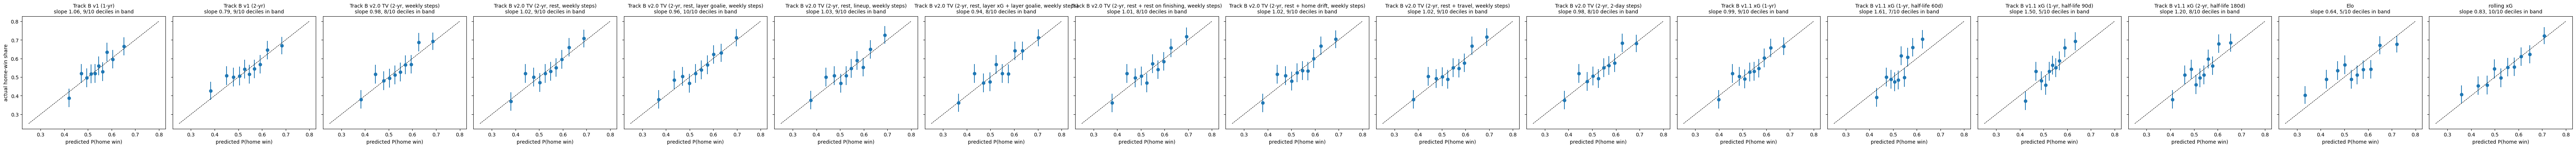

In [5]:
show = [m for m in MODELS if m != "home rate"]
fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4.2), sharey=True)
for ax, name in zip(np.atleast_1d(axes), show):
    t = calibration_table(df[MODELS[name]], df["home_won"], bins=10)
    a, b = calibration_slope(df[MODELS[name]], df["home_won"])
    ax.errorbar(t.predicted, t.actual, yerr=t.band_90, fmt="o")
    ax.plot([0.25, 0.8], [0.25, 0.8], "k--", lw=0.8)
    ax.set_title(f"{name}\nslope {b:.2f}, {int(t.inside.sum())}/{len(t)} deciles in band", fontsize=10)
    ax.set_xlabel("predicted P(home win)")
np.atleast_1d(axes)[0].set_ylabel("actual home-win share")
plt.tight_layout()

slopes = tables["combined"][["model", "calibration slope", "slope 90%", "intercept"]]
display(slopes.round(3))
for name in tb_names:
    b = comb.loc[name, "calibration slope"]
    rng_ = comb.loc[name, "slope 90%"]
    lo = float(rng_.strip("[]").split(",")[0])
    check(f"{name}: not clearly too cautious (90% range of slope includes 1 or lies below)", lo <= 1.0,
          f"slope {b:.2f} {rng_}")

## 6. Calibration over the season

If static ratings are the problem, early-season games (before this season's results have moved the ratings)
should look worst: calibration slope well above 1 in October-November, closer to 1 later.

,model,month,games,log loss,calibration slope,mean predicted,actual
0,Track B v1 (1-yr),2024-10,166,0.667,1.248,0.535,0.530
1,Track B v1 (1-yr),2024-11,220,0.676,1.038,0.533,0.536
2,Track B v1 (1-yr),2024-12,214,0.669,1.160,0.534,0.561
3,Track B v1 (1-yr),2025-01,224,0.677,1.021,0.534,0.558
4,Track B v1 (1-yr),2025-02,122,0.661,2.195,0.535,0.549
5,Track B v1 (1-yr),2025-03,234,0.650,2.238,0.542,0.598
6,Track B v1 (1-yr),2025-04,132,0.675,0.646,0.546,0.606
7,Track B v1 (1-yr),2025-10,180,0.690,0.656,0.542,0.528
8,Track B v1 (1-yr),2025-11,225,0.693,0.520,0.543,0.520
9,Track B v1 (1-yr),2025-12,226,0.706,-0.227,0.548,0.504


,model,month,games,log loss,calibration slope,mean predicted,actual
0,Track B v1 (2-yr),2024-10,166,0.669,0.974,0.534,0.530
1,Track B v1 (2-yr),2024-11,220,0.679,0.780,0.528,0.536
2,Track B v1 (2-yr),2024-12,214,0.662,1.079,0.535,0.561
3,Track B v1 (2-yr),2025-01,224,0.683,0.618,0.534,0.558
4,Track B v1 (2-yr),2025-02,122,0.660,1.460,0.526,0.549
5,Track B v1 (2-yr),2025-03,234,0.652,1.465,0.537,0.598
6,Track B v1 (2-yr),2025-04,132,0.675,0.677,0.539,0.606
7,Track B v1 (2-yr),2025-10,180,0.694,0.404,0.538,0.528
8,Track B v1 (2-yr),2025-11,225,0.694,0.457,0.535,0.520
9,Track B v1 (2-yr),2025-12,226,0.704,0.122,0.542,0.504


,model,month,games,log loss,calibration slope,mean predicted,actual
0,"Track B v2.0 TV (2-yr, weekly steps)",2024-10,166,0.664,1.101,0.534,0.530
1,"Track B v2.0 TV (2-yr, weekly steps)",2024-11,220,0.671,1.008,0.528,0.536
2,"Track B v2.0 TV (2-yr, weekly steps)",2024-12,214,0.654,1.421,0.534,0.561
3,"Track B v2.0 TV (2-yr, weekly steps)",2025-01,224,0.680,0.708,0.532,0.558
4,"Track B v2.0 TV (2-yr, weekly steps)",2025-02,122,0.667,1.270,0.530,0.549
5,"Track B v2.0 TV (2-yr, weekly steps)",2025-03,234,0.647,1.653,0.540,0.598
6,"Track B v2.0 TV (2-yr, weekly steps)",2025-04,132,0.681,0.500,0.535,0.606
7,"Track B v2.0 TV (2-yr, weekly steps)",2025-10,180,0.691,0.511,0.536,0.528
8,"Track B v2.0 TV (2-yr, weekly steps)",2025-11,225,0.689,0.658,0.541,0.520
9,"Track B v2.0 TV (2-yr, weekly steps)",2025-12,226,0.690,0.748,0.539,0.504


,model,month,games,log loss,calibration slope,mean predicted,actual
0,"Track B v2.0 TV (2-yr, rest, weekly steps)",2024-10,166,0.662,1.128,0.534,0.530
1,"Track B v2.0 TV (2-yr, rest, weekly steps)",2024-11,220,0.670,1.038,0.528,0.536
2,"Track B v2.0 TV (2-yr, rest, weekly steps)",2024-12,214,0.648,1.566,0.534,0.561
3,"Track B v2.0 TV (2-yr, rest, weekly steps)",2025-01,224,0.680,0.722,0.532,0.558
4,"Track B v2.0 TV (2-yr, rest, weekly steps)",2025-02,122,0.666,1.251,0.532,0.549
5,"Track B v2.0 TV (2-yr, rest, weekly steps)",2025-03,234,0.645,1.683,0.541,0.598
6,"Track B v2.0 TV (2-yr, rest, weekly steps)",2025-04,132,0.679,0.541,0.538,0.606
7,"Track B v2.0 TV (2-yr, rest, weekly steps)",2025-10,180,0.689,0.606,0.536,0.528
8,"Track B v2.0 TV (2-yr, rest, weekly steps)",2025-11,225,0.686,0.789,0.540,0.520
9,"Track B v2.0 TV (2-yr, rest, weekly steps)",2025-12,226,0.686,0.864,0.536,0.504


,model,month,games,log loss,calibration slope,mean predicted,actual
0,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2024-10,166,0.661,1.065,0.532,0.530
1,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2024-11,220,0.676,0.842,0.528,0.536
2,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2024-12,214,0.648,1.426,0.535,0.561
3,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2025-01,224,0.677,0.761,0.532,0.558
4,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2025-02,122,0.668,1.089,0.531,0.549
5,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2025-03,234,0.642,1.599,0.540,0.598
6,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2025-04,132,0.677,0.584,0.540,0.606
7,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2025-10,180,0.695,0.383,0.535,0.528
8,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2025-11,225,0.685,0.759,0.538,0.520
9,"Track B v2.0 TV (2-yr, rest, layer goalie, wee...",2025-12,226,0.683,0.964,0.535,0.504


,model,month,games,log loss,calibration slope,mean predicted,actual
0,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2024-10,166,0.663,1.143,0.534,0.530
1,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2024-11,220,0.667,1.123,0.528,0.536
2,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2024-12,214,0.646,1.515,0.533,0.561
3,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2025-01,224,0.682,0.638,0.532,0.558
4,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2025-02,122,0.660,1.517,0.530,0.549
5,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2025-03,234,0.643,1.733,0.541,0.598
6,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2025-04,132,0.673,0.704,0.541,0.606
7,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2025-10,180,0.691,0.504,0.536,0.528
8,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2025-11,225,0.687,0.717,0.538,0.520
9,"Track B v2.0 TV (2-yr, rest, lineup, weekly st...",2025-12,226,0.690,0.696,0.537,0.504


... (21 outputs left out)

,model,season,games,log loss,calibration slope,mean predicted,actual
0,Track B v1.1 xG (1-yr),20242025,1312,0.6670,1.1319,0.5363,0.5625
1,Track B v1.1 xG (1-yr),20252026,1312,0.6877,0.7762,0.5393,0.5221


,model,season,games,log loss,calibration slope,mean predicted,actual
0,"Track B v1.1 xG (1-yr, half-life 60d)",20242025,1312,0.6700,1.7436,0.5309,0.5625
1,"Track B v1.1 xG (1-yr, half-life 60d)",20252026,1312,0.6841,1.3668,0.5232,0.5221


,model,season,games,log loss,calibration slope,mean predicted,actual
0,"Track B v1.1 xG (1-yr, half-life 90d)",20242025,1312,0.6683,1.6212,0.5324,0.5625
1,"Track B v1.1 xG (1-yr, half-life 90d)",20252026,1312,0.6841,1.2816,0.5269,0.5221


,model,season,games,log loss,calibration slope,mean predicted,actual
0,"Track B v1.1 xG (2-yr, half-life 180d)",20242025,1312,0.6673,1.3142,0.5332,0.5625
1,"Track B v1.1 xG (2-yr, half-life 180d)",20252026,1312,0.6854,1.0176,0.5331,0.5221


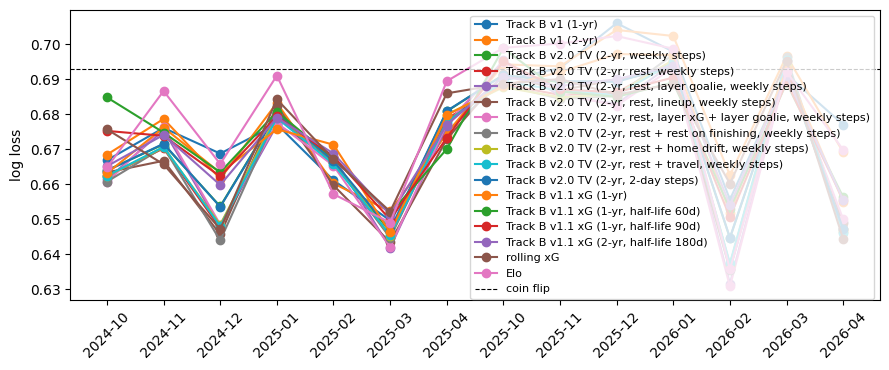

In [6]:
for name in tb_names + ["rolling xG"]:
    g = by_group(df, MODELS[name], "month")
    g.insert(0, "model", name)
    display(g.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
for name in tb_names + ["rolling xG", "Elo"]:
    g = by_group(df, MODELS[name], "month")
    ax.plot(g["month"], g["log loss"], marker="o", label=name)
ax.axhline(0.6931, color="k", lw=0.8, ls="--", label="coin flip")
ax.set_ylabel("log loss"); ax.legend(fontsize=8); plt.xticks(rotation=45)
plt.tight_layout()

for name in tb_names:
    g = by_group(df, MODELS[name], "season")
    g.insert(0, "model", name)
    display(g.round(4))

## 7. Uncertainty intervals on P(win)

The 90% interval reflects how unsure Track B is about the two teams. It can't be checked against a single
outcome, but two things should hold: intervals narrow as a season goes on (more data), and games where the model
is unsure (wide interval) should be harder to predict.

In [7]:
df = df.copy()   # one block in memory (silences pandas' fragmentation warning)
for lab in AVAILABLE:
    w = display_name(lab)
    width = df[f"p_home_hi_{lab}"] - df[f"p_home_lo_{lab}"]
    by_m = df.assign(width=width).groupby("month")["width"].median()
    print(f"{w}: median 90% interval width {width.median():.1%}")
    display(by_m.to_frame("median width").T.round(3))
    terc = pd.qcut(width, 3, labels=["narrow", "middle", "wide"])
    t = df.assign(t=terc).groupby("t", observed=True).apply(
        lambda s: pd.Series({"games": len(s), "log loss": log_loss(s[f"p_home_{lab}"], s.home_won)}), include_groups=False)
    display(t.round(4))

Track B v1 (1-yr): median 90% interval width 15.3%


month,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
median width,0.171,0.169,0.167,0.16,0.158,0.159,0.158,0.151,0.14,0.144,0.144,0.145,0.141,0.138


,games,log loss
t,,
narrow,875.0,0.6921
middle,874.0,0.6718
wide,875.0,0.6755


Track B v1 (2-yr): median 90% interval width 12.6%


month,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
median width,0.131,0.131,0.129,0.129,0.129,0.128,0.127,0.126,0.123,0.124,0.123,0.122,0.122,0.119


,games,log loss
t,,
narrow,875.0,0.6772
middle,874.0,0.6771
wide,875.0,0.6890


... (35 outputs left out)

,games,log loss
t,,
narrow,875.0,0.6636
middle,874.0,0.6862
wide,875.0,0.6786


Track B v1.1 xG (2-yr, half-life 180d): median 90% interval width 11.1%


month,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
median width,0.131,0.123,0.117,0.11,0.106,0.105,0.106,0.125,0.116,0.112,0.108,0.107,0.107,0.102


,games,log loss
t,,
narrow,875.0,0.6704
middle,874.0,0.6731
wide,875.0,0.6855


## 8. Score outputs: totals and puck lines

Brier scores (lower is better) for over/under 5.5 and 6.5 and both puck lines, against simply predicting each
market's historical rate from earlier seasons. Total goals scored with the ranked probability score.

In [8]:
conn = get_connection()
hist = pd.read_sql("SELECT season, home_score, away_score FROM games WHERE game_type = 2 AND home_score IS NOT NULL", conn)
hist["season"] = hist["season"].astype(str)
for s in sorted(df.season.unique()):
    for lab in AVAILABLE:
        f = BT / f"{lab}_{s}_scored.csv"
        if not f.exists():
            continue
        d = pd.read_csv(f)
        past = hist[hist.season < s]
        tot, mar = past.home_score + past.away_score, past.home_score - past.away_score
        clim = {"over 5.5": (tot > 5.5).mean(), "over 6.5": (tot > 6.5).mean(),
                "home -1.5": (mar >= 2).mean(), "away -1.5": (mar <= -2).mean()}
        so = score_outputs(d, clim)
        print(f"\n{s}, {display_name(lab)}")
        display(so.round(4))


20242025, Track B v1 (1-yr)


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5428,0.5373,0.2499,0.2507
1,over 6.5,0.4394,0.4230,0.2453,0.2465
2,home -1.5,0.3338,0.3537,0.2247,0.2292
3,away -1.5,0.2718,0.2637,0.1903,0.1944
4,total goals (RPS),6.1255,6.0808,0.0928,NaN



20242025, Track B v1 (2-yr)


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5629,0.5373,0.2490,0.2507
1,over 6.5,0.4599,0.4230,0.2457,0.2465
2,home -1.5,0.3276,0.3537,0.2261,0.2292
3,away -1.5,0.2705,0.2637,0.1904,0.1944
4,total goals (RPS),6.2451,6.0808,0.0928,NaN



20242025, Track B v2.0 TV (2-yr, weekly steps)


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5393,0.5373,0.2488,0.2507
1,over 6.5,0.4364,0.4230,0.2445,0.2465
2,home -1.5,0.3256,0.3537,0.2241,0.2292
3,away -1.5,0.2686,0.2637,0.1895,0.1944
4,total goals (RPS),6.1074,6.0808,0.0926,NaN


... (50 outputs left out)


20252026, Track B v1.1 xG (1-yr, half-life 90d)


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5594,0.5732,0.2434,0.2446
1,over 6.5,0.4534,0.4688,0.2475,0.2491
2,home -1.5,0.3270,0.3011,0.2074,0.2116
3,away -1.5,0.2802,0.2668,0.1923,0.1957
4,total goals (RPS),6.2151,6.2538,0.0909,NaN



20252026, Track B v1.1 xG (2-yr, half-life 180d)


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5511,0.5732,0.2434,0.2446
1,over 6.5,0.4459,0.4688,0.2477,0.2491
2,home -1.5,0.3318,0.3011,0.2079,0.2116
3,away -1.5,0.2747,0.2668,0.1928,0.1957
4,total goals (RPS),6.1664,6.2538,0.0908,NaN


## 9. Combining Track B and rolling xG

Track B sees goals, rolling xG sees shot quality. If averaging them beats both, each has information the other lacks,
which is the case for adding xG to Track B (v2.3).

In [9]:
for name in tb_names:
    col = MODELS[name]
    df["p_blend"] = 0.5 * df[col] + 0.5 * df["p_rolling_xg"]
    print(f"\n{name} + rolling xG")
    blend = score_models(df, {name: col, "rolling xG": "p_rolling_xg", "50/50 blend": "p_blend"})
    display(blend.drop(columns=["games"]).round(4))
    r = paired_difference(df, "p_blend", col)
    check("blend beats this Track B alone", r["difference"] < 0,
          f"{r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]; for v1.1, not beating it means xG is already inside")
    r = paired_difference(df, "p_blend", "p_rolling_xg")
    check("blend beats rolling xG alone", r["difference"] < 0,
          f"{r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")


Track B v1 (1-yr) + rolling xG


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept
0,Track B v1 (1-yr),0.6798,0.2434,0.5644,1.0638,"[0.82, 1.28]",0.0080
1,rolling xG,0.6754,0.2413,0.5766,0.8341,"[0.70, 0.98]",0.0417
2,50/50 blend,0.6744,0.2408,0.5705,1.1643,"[0.98, 1.35]",-0.0070


PASS   blend beats this Track B alone   (-0.0054 [-0.0078, -0.0029]; for v1.1, not beating it means xG is already inside)
PASS   blend beats rolling xG alone   (-0.0010 [-0.0035, +0.0015])

Track B v1 (2-yr) + rolling xG


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept
0,Track B v1 (2-yr),0.6811,0.2441,0.5606,0.7858,"[0.59, 0.95]",0.0566
1,rolling xG,0.6754,0.2413,0.5766,0.8341,"[0.70, 0.98]",0.0417
2,50/50 blend,0.6749,0.2411,0.5652,1.0128,"[0.84, 1.17]",0.0202


PASS   blend beats this Track B alone   (-0.0062 [-0.0088, -0.0037]; for v1.1, not beating it means xG is already inside)
PASS   blend beats rolling xG alone   (-0.0005 [-0.0032, +0.0021])

Track B v2.0 TV (2-yr, weekly steps) + rolling xG


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept
0,"Track B v2.0 TV (2-yr, weekly steps)",0.6749,0.2411,0.5713,0.9828,"[0.80, 1.15]",0.0289
1,rolling xG,0.6754,0.2413,0.5766,0.8341,"[0.70, 0.98]",0.0417
2,50/50 blend,0.6738,0.2406,0.5701,0.9692,"[0.82, 1.12]",0.0263


... (21 outputs left out)

,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept
0,"Track B v1.1 xG (1-yr, half-life 90d)",0.6762,0.2416,0.5655,1.4999,"[1.24, 1.73]",-0.0056
1,rolling xG,0.6754,0.2413,0.5766,0.8341,"[0.70, 0.98]",0.0417
2,50/50 blend,0.6738,0.2405,0.5694,1.1677,"[0.99, 1.35]",0.0128


PASS   blend beats this Track B alone   (-0.0023 [-0.0042, -0.0004]; for v1.1, not beating it means xG is already inside)
PASS   blend beats rolling xG alone   (-0.0015 [-0.0035, +0.0004])

Track B v1.1 xG (2-yr, half-life 180d) + rolling xG


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept
0,"Track B v1.1 xG (2-yr, half-life 180d)",0.6763,0.2417,0.5568,1.2031,"[0.97, 1.41]",0.0113
1,rolling xG,0.6754,0.2413,0.5766,0.8341,"[0.70, 0.98]",0.0417
2,50/50 blend,0.6741,0.2407,0.5671,1.0811,"[0.91, 1.26]",0.0163


PASS   blend beats this Track B alone   (-0.0023 [-0.0040, -0.0005]; for v1.1, not beating it means xG is already inside)
PASS   blend beats rolling xG alone   (-0.0013 [-0.0032, +0.0005])


## 10. Market comparison

Needs `data/external/closing_lines.csv` with columns `date, home, away, home_ml, away_ml` (American odds,
team abbreviations as in the database). Implied probabilities have the bookmaker's margin removed
(each divided by their sum).

In [10]:
from config.settings import PROJECT_ROOT
odds_path = PROJECT_ROOT / "data" / "external" / "closing_lines.csv"
if not odds_path.exists():
    print(f"No market data yet ({odds_path}). Add the file and rerun this section.")
else:
    def implied(ml):
        ml = ml.astype(float)
        return np.where(ml < 0, -ml / (-ml + 100), 100 / (ml + 100))
    odds = pd.read_csv(odds_path, parse_dates=["date"])
    odds["raw_home"], odds["raw_away"] = implied(odds.home_ml), implied(odds.away_ml)
    odds["overround"] = odds.raw_home + odds.raw_away
    odds["p_market"] = odds.raw_home / odds.overround
    m = df.merge(odds[["date", "home", "away", "p_market", "overround"]],
                 left_on=[df.game_date.dt.normalize(), "home", "away"], right_on=["date", "home", "away"], how="inner")
    print(f"matched {len(m):,} of {len(df):,} games; average bookmaker margin {m.overround.mean() - 1:.1%}")
    t = score_models(m, {**{k: v for k, v in MODELS.items() if k != "home rate"}, "market": "p_market"},
                     reference="market")
    display(t.drop(columns=["games"]).round(4))
    for name in tb_names:
        r = paired_difference(m, MODELS[name], "p_market")
        print(f"{name} vs market: {r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] (negative = model better)")

No market data yet (c:\Users\ckief\personal_projects\hockey_stats_code\notebooks\..\data\external\closing_lines.csv). Add the file and rerun this section.


## 11. v2.0 verdict: did time-varying ratings close the gap?

v2.0 is kept if, on the same games, it (1) beats v1.1 (1-yr), (2) ideally beats rolling xG, (3) stays calibrated
(slope range includes 1), and (4) **blending with rolling xG stops helping**: if a 50/50 blend still beats v2.0,
recent form is not fully captured yet. Weekly vs 2-day steps: keep the 2-day version only if it is clearly better.

**v2.0d (rest, home drift):** the last block compares every v2.0 variant with plain weekly v2.0 on the same games.
A variant is kept only if it is **clearly better** (whole range below zero); rest + home drift is kept over rest
alone only if it is clearly better than rest alone (run `paired_difference` on those two if both are close).

**v2.0e (rest on finishing / goaltending):** the final block compares each variant built on rest with the
**live model, v2.0 + rest**. Adopt only if clearly better (whole range below zero).
**v2.0f (travel):** same rule, `trackbtv_w730_rt` against the live model in that final block.
**v2.0g (goalie on zero rest):** same rule, `trackbtv_w730_rk` against the live model.
**v2.1 (xG layer):** `trackbtv_w730_r_lg` (layer goalie rating) and `_r_lxg` (+ shooter-adjusted team xG) against the live model, same rule.
**v2.2 (lineup model):** `trackbtv_w730_r_lu` against the live model, same rule.


In [11]:
tv_names = [m for m in MODELS if "v2.0" in m]
v11 = [m for m in MODELS if m.startswith("Track B v1.1") and "half-life" not in m and "1-yr" in m]
if not tv_names:
    print("No v2.0 backtests yet (trackbtv_*_scored.csv).")
for name in tv_names:
    col = MODELS[name]
    print(f"\n=== {name} ===")
    for ref in v11 + ["rolling xG"]:
        r = paired_difference(df, col, MODELS[ref])
        check(f"beats {ref}", r["difference"] < 0,
              f"{r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]  "
              + ("clear" if r["hi"] < 0 else "within luck" if r["lo"] < 0 else "worse"))
    b = comb.loc[name, "calibration slope"]; rng_ = comb.loc[name, "slope 90%"]
    lo, hi = (float(x) for x in rng_.strip("[]").split(","))
    check("calibrated (slope range includes 1)", lo <= 1.0 <= hi, f"slope {b:.2f} {rng_}")
    blend = 0.5 * df[col] + 0.5 * df["p_rolling_xg"]
    r = paired_difference(df.assign(p_blend=blend), "p_blend", col)
    check("blending with rolling xG no longer helps", r["hi"] >= 0,
          f"blend minus v2.0 {r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")
# Each v2.0 variant against plain v2.0 (weekly steps, no rest / home terms)
plain = [m for m in tv_names if m.endswith("(2-yr, weekly steps)")]
if plain and len(tv_names) >= 2:
    base = plain[0]
    print(f"\n=== Variants vs {base} (negative = variant better) ===")
    for name in tv_names:
        if name == base:
            continue
        r = paired_difference(df, MODELS[name], MODELS[base])
        verdict = "clearly better" if r["hi"] < 0 else "clearly worse" if r["lo"] > 0 else "within luck"
        print(f"  {name}: {r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]  {verdict}")

# v2.0e: each variant built on rest against the live model, v2.0 + rest (negative = variant better)
live = [m for m in tv_names if m.endswith("(2-yr, rest, weekly steps)")]
on_rest = [m for m in tv_names if "rest" in m and live and m != live[0]]   # everything built on the live model
if live and on_rest:
    print(f"\n=== Variants vs the live model, {live[0]} (negative = variant better) ===")
    for name in on_rest:
        r = paired_difference(df, MODELS[name], MODELS[live[0]])
        verdict = "clearly better: adopt" if r["hi"] < 0 else "clearly worse" if r["lo"] > 0 else "within luck: keep the simpler model"
        print(f"  {name}: {r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]  {verdict}")



=== Track B v2.0 TV (2-yr, weekly steps) ===
PASS   beats Track B v1.1 xG (1-yr)   (-0.0025 [-0.0040, -0.0009]  clear)
PASS   beats rolling xG   (-0.0005 [-0.0038, +0.0027]  within luck)
PASS   calibrated (slope range includes 1)   (slope 0.98 [0.80, 1.15])
PASS   blending with rolling xG no longer helps   (blend minus v2.0 -0.0011 [-0.0026, +0.0006])

=== Track B v2.0 TV (2-yr, rest, weekly steps) ===
PASS   beats Track B v1.1 xG (1-yr)   (-0.0041 [-0.0059, -0.0023]  clear)
PASS   beats rolling xG   (-0.0021 [-0.0056, +0.0013]  within luck)
PASS   calibrated (slope range includes 1)   (slope 1.02 [0.83, 1.19])
PASS   blending with rolling xG no longer helps   (blend minus v2.0 -0.0004 [-0.0021, +0.0013])

=== Track B v2.0 TV (2-yr, rest, layer goalie, weekly steps) ===
PASS   beats Track B v1.1 xG (1-yr)   (-0.0044 [-0.0067, -0.0019]  clear)
PASS   beats rolling xG   (-0.0024 [-0.0062, +0.0015]  within luck)
PASS   calibrated (slope range includes 1)   (slope 0.96 [0.79, 1.11])
PASS 